In [1]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


/home/lihaoxing/tmp/ipykernel_437218/2761727322.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

IVF-2C-R1 vs. IVF-2C-R2: Mann-Whitney-Wilcoxon test two-sided, P_val:5.289e-05 U_stat=3.570e+02
IVF-4C-R1 vs. IVF-4C-R2: Mann-Whitney-Wilcoxon test two-sided, P_val:2.885e-08 U_stat=6.630e+02


/home/lihaoxing/tmp/ipykernel_437218/2761727322.py:173: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(


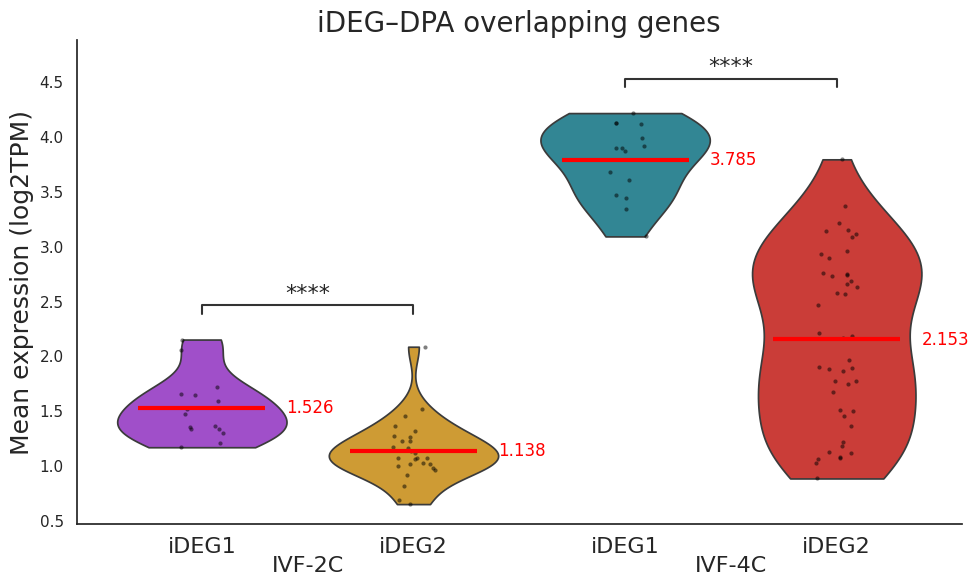

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False

sns.set(style="white")  # ⭐统一风格（无grid）

# =========================
# function：构建violin数据
# =========================
def build_violin(expr_file, group_file, gene_list, stage):
    expr = pd.read_csv(expr_file, sep="\t", index_col=0)
    group_info = pd.read_csv(group_file, sep="\t", header=None, names=["cell", "group"])
    group_dict = dict(zip(group_info["cell"], group_info["group"]))

    cells = [c for c in expr.columns if c in group_dict]
    expr = expr[cells]

    group_df = pd.DataFrame({
        "cell": expr.columns,
        "group": [group_dict[c] for c in expr.columns]
    })

    expr_sub = expr.loc[expr.index.intersection(gene_list)]

    g1 = group_df["group"].unique()[1]
    g2 = group_df["group"].unique()[0]

    g1_cells = group_df[group_df["group"] == g1]["cell"]
    g2_cells = group_df[group_df["group"] == g2]["cell"]

    v1 = expr_sub[g1_cells].mean()
    v2 = expr_sub[g2_cells].mean()

    df = pd.DataFrame({
        "value": list(v1) + list(v2),
        "group": [f"{stage}-R1"] * len(v1) + [f"{stage}-R2"] * len(v2)
    })

    return df, [f"{stage}-R1", f"{stage}-R2"]

# =========================
# gene sets
# =========================
with open("ivf_429.txt") as f:
    dpa_genes = [x.strip() for x in f if x.strip()]

# =========================
# build data
# =========================
df2c, order2c = build_violin(
    "IVF_2C_all_log2TPM_dip.txt",
    "IVF_2C_group.txt",
    dpa_genes,
    "IVF-2C"
)

df4c, order4c = build_violin(
    "IVF_4C_all_log2TPM_dip.txt",
    "IVF_4C_group.txt",
    dpa_genes,
    "IVF-4C"
)

df2c["stage"] = "2C"
df4c["stage"] = "4C"

df = pd.concat([df2c, df4c], ignore_index=True)

# =========================
# figure
# =========================
fig, ax = plt.subplots(figsize=(10, 6))

palette = {
    "IVF-2C-R1": "#A73BDD",
    "IVF-2C-R2": "#E7A31B",
    "IVF-4C-R1": "#2292A4",
    "IVF-4C-R2": "#E22720"
}

order = ["IVF-2C-R1", "IVF-2C-R2", "IVF-4C-R1", "IVF-4C-R2"]

# =========================
# violin
# =========================
sns.violinplot(
    x="group",
    y="value",
    data=df,
    order=order,
    palette=palette,
    inner=None,
    cut=0,
    ax=ax
)

# =========================
# scatter（黑点）
# =========================
sns.stripplot(
    x="group",
    y="value",
    data=df,
    order=order,
    color="black",
    size=3,
    alpha=0.5,
    ax=ax
)

# =========================
# mean line + value（红色）
# =========================
means = df.groupby("group")["value"].mean()

for i, g in enumerate(order):
    m = means[g]

    ax.hlines(
        y=m,
        xmin=i - 0.3,
        xmax=i + 0.3,
        color="red",
        linewidth=3,
        zorder=5
    )

    ax.text(
        i + 0.4,
        m,
        f"{m:.3f}",
        color="red",
        ha="left",
        va="center",
        fontsize=12
    )

# =========================
# significance（图内）
# =========================
pairs = [
    ("IVF-2C-R1", "IVF-2C-R2"),
    ("IVF-4C-R1", "IVF-4C-R2")
]

annotator = Annotator(
    ax,
    pairs,
    data=df,
    x="group",
    y="value",
    order=order
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    fontsize=16
)

annotator.apply_and_annotate()

# =========================
# x labels
# =========================
ax.set_xticklabels(
    ["iDEG1", "iDEG2", "iDEG1", "iDEG2"],
    fontsize=16
)

# group label
ax.text(0.5, -0.10, "IVF-2C",
        transform=ax.get_xaxis_transform(),
        ha="center", fontsize=16)

ax.text(2.5, -0.10, "IVF-4C",
        transform=ax.get_xaxis_transform(),
        ha="center", fontsize=16)

# =========================
# style
# =========================
ax.set_ylabel("Mean expression (log2TPM)", fontsize=18)
ax.set_xlabel("")
ax.set_title("iDEG–DPA overlapping genes", fontsize=20)

ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig("IVF_2C_4C_iDEG_DPA_merged.svg", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_437218/553487570.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

IVF-2C-iDET1 vs. IVF-2C-iDET2: Mann-Whitney-Wilcoxon test two-sided, P_val:8.056e-01 U_stat=1.980e+02
IVF-4C-iDET1 vs. IVF-4C-iDET2: Mann-Whitney-Wilcoxon test two-sided, P_val:1.281e-05 U_stat=7.350e+02


/home/lihaoxing/tmp/ipykernel_437218/553487570.py:176: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(


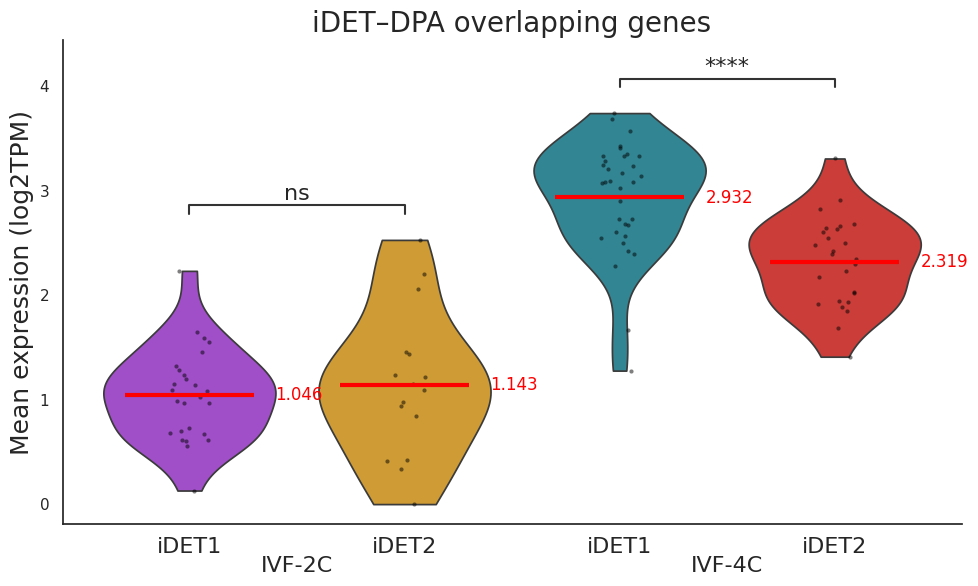

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import numpy as np

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

sns.set(style="white")  # clean style

# =========================
# function
# =========================
def build_violin(expr_file, group_file, gene_file, stage_prefix):

    expr = pd.read_csv(expr_file, sep="\t", index_col=0)
    group_info = pd.read_csv(group_file, sep="\t", header=None, names=["cell", "group"])
    group_dict = dict(zip(group_info["cell"], group_info["group"]))

    cells = [c for c in expr.columns if c in group_dict]
    expr = expr[cells]

    group_df = pd.DataFrame({
        "cell": expr.columns,
        "group": [group_dict[c] for c in expr.columns]
    })

    with open(gene_file) as f:
        genes = [x.strip() for x in f if x.strip()]

    expr_sub = expr.loc[expr.index.intersection(genes)]

    g1 = group_df["group"].unique()[0]
    g2 = group_df["group"].unique()[1]

    g1_cells = group_df[group_df["group"] == g1]["cell"]
    g2_cells = group_df[group_df["group"] == g2]["cell"]

    v1 = expr_sub[g1_cells].mean()
    v2 = expr_sub[g2_cells].mean()

    df = pd.DataFrame({
        "value": list(v1) + list(v2),
        "group": [f"{stage_prefix}-iDET1"] * len(v1) + [f"{stage_prefix}-iDET2"] * len(v2)
    })

    return df


# =========================
# build datasets
# =========================
df2c = build_violin(
    "IVF_2C_all_log2TPM_dip.txt",
    "IVF_2C_iDET_cluster.txt",
    "IVF_R2C_iDET_DPA_overlap_id.txt",
    "IVF-2C"
)

df4c = build_violin(
    "IVF_4C_all_log2TPM_dip.txt",
    "IVF_4C_iDET_cluster.txt",
    "IVF_R4C_iDET_DPA_overlap_id.txt",
    "IVF-4C"
)

df2c["stage"] = "2C"
df4c["stage"] = "4C"

df = pd.concat([df2c, df4c], ignore_index=True)

# =========================
# order + palette (keep yours)
# =========================
order = [
    "IVF-2C-iDET1",
    "IVF-2C-iDET2",
    "IVF-4C-iDET1",
    "IVF-4C-iDET2"
]

palette = {
    "IVF-2C-iDET1": "#A73BDD",
    "IVF-2C-iDET2": "#E7A31B",
    "IVF-4C-iDET1": "#2292A4",
    "IVF-4C-iDET2": "#E22720"
}

# =========================
# figure
# =========================
fig, ax = plt.subplots(figsize=(10, 6))

# violin
sns.violinplot(
    x="group",
    y="value",
    data=df,
    order=order,
    palette=palette,
    inner=None,
    cut=0,
    ax=ax
)

# black dots
sns.stripplot(
    x="group",
    y="value",
    data=df,
    order=order,
    color="black",
    size=3,
    alpha=0.5,
    ax=ax
)

# =========================
# mean line + value (red)
# =========================
means = df.groupby("group")["value"].mean()

for i, g in enumerate(order):
    m = means[g]

    ax.hlines(
        y=m,
        xmin=i - 0.3,
        xmax=i + 0.3,
        color="red",
        linewidth=3,
        zorder=5
    )

    ax.text(
        i + 0.4,
        m,
        f"{m:.3f}",
        color="red",
        ha="left",
        va="center",
        fontsize=12
    )

# =========================
# significance
# =========================
pairs = [
    ("IVF-2C-iDET1", "IVF-2C-iDET2"),
    ("IVF-4C-iDET1", "IVF-4C-iDET2")
]

annotator = Annotator(
    ax,
    pairs,
    data=df,
    x="group",
    y="value",
    order=order
)

annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    fontsize=16
)

annotator.apply_and_annotate()

# =========================
# labels
# =========================
ax.set_xticklabels(
    ["iDET1", "iDET2", "iDET1", "iDET2"],
    fontsize=16
)

ax.text(0.5, -0.10, "IVF-2C",
        transform=ax.get_xaxis_transform(),
        ha="center", fontsize=16)

ax.text(2.5, -0.10, "IVF-4C",
        transform=ax.get_xaxis_transform(),
        ha="center", fontsize=16)

# =========================
# style
# =========================
ax.set_ylabel("Mean expression (log2TPM)", fontsize=18)
ax.set_xlabel("")
ax.set_title("iDET–DPA overlapping genes", fontsize=20)

ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig("IVF_2C_4C_iDET_DPA_merged.svg", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

PA-2C p-value (Mann-Whitney) = 0.012266061386212971


/home/lihaoxing/tmp/ipykernel_437218/3840221917.py:94: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="group", y="value", data=df, order=order, palette=palette,


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

PA-2C-R1 vs. PA-2C-R2: Mann-Whitney-Wilcoxon test two-sided, P_val:1.227e-02 U_stat=1.100e+02
PA-4C-R1 vs. PA-4C-R2: Mann-Whitney-Wilcoxon test two-sided, P_val:2.917e-02 U_stat=2.500e+02


/home/lihaoxing/tmp/ipykernel_437218/3840221917.py:115: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(["iDEG1", "iDEG2", "iDEG1", "iDEG2"], fontsize=16)


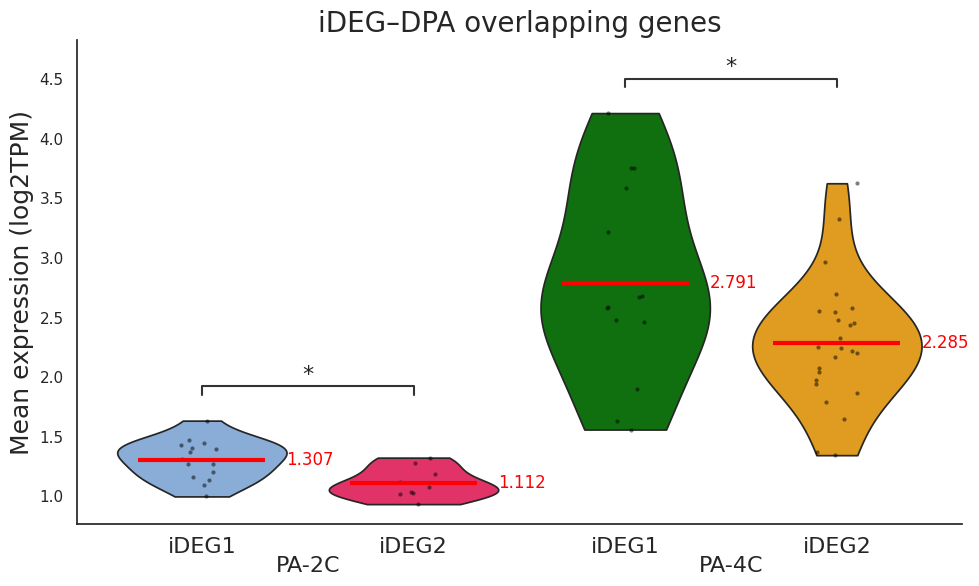

In [4]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
from scipy.stats import mannwhitneyu  # 可选，用于验证

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False
sns.set(style="white")

# ============================
# 1. 定义函数：完全按照原代码逻辑提取每个阶段的均值数据
# ============================
def get_stage_means(expr_file, group_file, gene_file, stage_name, group1_name, group2_name):
    """
    按照原始代码的逻辑，返回该阶段两个重复组的均值 Series
    """
    expr = pd.read_csv(expr_file, sep="\t", index_col=0)
    group_info = pd.read_csv(group_file, sep="\t", header=None, names=["cell", "group"])
    group_dict = dict(zip(group_info["cell"], group_info["group"]))

    # 保留有效细胞
    cells_in_use = [c for c in expr.columns if c in group_dict]
    expr = expr[cells_in_use]

    # 读取基因集
    with open(gene_file) as f:
        target_genes = [line.strip() for line in f if line.strip()]
    expr_target = expr.loc[expr.index.intersection(target_genes)]

    # 提取两组细胞的均值（每个细胞一个均值）
    cells_r1 = [c for c, g in group_dict.items() if g == group1_name]
    cells_r2 = [c for c, g in group_dict.items() if g == group2_name]

    means_r1 = expr_target[cells_r1].mean()  # Series, index=cell
    means_r2 = expr_target[cells_r2].mean()

    # 构建 DataFrame，group 列名与 stage_name 对应，方便合并
    df_stage = pd.DataFrame({
        "value": list(means_r1) + list(means_r2),
        "group": [f"{stage_name}-R1"] * len(means_r1) + [f"{stage_name}-R2"] * len(means_r2)
    })
    df_stage["stage"] = stage_name
    return df_stage

# ============================
# 2. 获取 PA-2C 和 PA-4C 的数据（注意组名要和原始文件中的完全一致）
# ============================
df_2c = get_stage_means(
    expr_file="PA_2C_all_log2TPM_dip.txt",
    group_file="PA_2C_group.txt",
    gene_file="pa_2c_73.txt",
    stage_name="PA-2C",
    group1_name="PA-2C-R1",   # 请确认原始分组文件中准确的名称
    group2_name="PA-2C-R2"
)

df_4c = get_stage_means(
    expr_file="PA_4C_all_log2TPM_dip.txt",
    group_file="PA_4C_group.txt",
    gene_file="pa_4c_167.txt",
    stage_name="PA-4C",
    group1_name="PA-4C-R1",   # 请确认原始分组文件中准确的名称
    group2_name="PA-4C-R2"
)

# 合并
df = pd.concat([df_2c, df_4c], ignore_index=True)

# ============================
# 3. 可选：验证 PA-2C 的 p 值是否与原代码一致
# ============================
from scipy.stats import mannwhitneyu
vals_2c_r1 = df[df["group"] == "PA-2C-R1"]["value"]
vals_2c_r2 = df[df["group"] == "PA-2C-R2"]["value"]
_, p_2c = mannwhitneyu(vals_2c_r1, vals_2c_r2)
print(f"PA-2C p-value (Mann-Whitney) = {p_2c}")

# ============================
# 4. 绘图（风格与原 IVF 合并图一致）
# ============================
order = ["PA-2C-R1", "PA-2C-R2", "PA-4C-R1", "PA-4C-R2"]
palette = {
    "PA-2C-R1": "#7dace4",
    "PA-2C-R2": "#ff165d",
    "PA-4C-R1": "green",
    "PA-4C-R2": "orange"
}

fig, ax = plt.subplots(figsize=(10, 6))

# 小提琴图
sns.violinplot(x="group", y="value", data=df, order=order, palette=palette,
               inner=None, cut=0, ax=ax)

# 散点图
sns.stripplot(x="group", y="value", data=df, order=order,
              color="black", size=3, alpha=0.5, ax=ax)

# 均值红线 + 数值
means = df.groupby("group")["value"].mean()
for i, g in enumerate(order):
    m = means[g]
    ax.hlines(y=m, xmin=i-0.3, xmax=i+0.3, color="red", linewidth=3, zorder=5)
    ax.text(i+0.4, m, f"{m:.3f}", color="red", ha="left", va="center", fontsize=12)

# 统计检验（每个阶段内）
pairs = [("PA-2C-R1", "PA-2C-R2"), ("PA-4C-R1", "PA-4C-R2")]
annotator = Annotator(ax, pairs, data=df, x="group", y="value", order=order)
annotator.configure(test="Mann-Whitney", text_format="star", loc="inside", fontsize=16)
annotator.apply_and_annotate()

# X 轴标签
ax.set_xticklabels(["iDEG1", "iDEG2", "iDEG1", "iDEG2"], fontsize=16)
ax.text(0.5, -0.10, "PA-2C", transform=ax.get_xaxis_transform(), ha="center", fontsize=16)
ax.text(2.5, -0.10, "PA-4C", transform=ax.get_xaxis_transform(), ha="center", fontsize=16)

ax.set_ylabel("Mean expression (log2TPM)", fontsize=18)
ax.set_xlabel("")
ax.set_title("iDEG–DPA overlapping genes", fontsize=20)
ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig("PA_2C_4C_iDEG_DPA_merged.svg", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

PA-2C Mann-Whitney p = 0.6768391567153177
PA-4C Mann-Whitney p = 0.03115061837043333


/home/lihaoxing/tmp/ipykernel_437218/339363835.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x="group", y="value", data=df, order=order, palette=palette,


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

PA-2C-R1 vs. PA-2C-R2: Mann-Whitney-Wilcoxon test two-sided, P_val:6.768e-01 U_stat=3.900e+01
PA-4C-R1 vs. PA-4C-R2: Mann-Whitney-Wilcoxon test two-sided, P_val:3.115e-02 U_stat=2.660e+02


/home/lihaoxing/tmp/ipykernel_437218/339363835.py:123: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(["iDET1", "iDET2", "iDET1", "iDET2"], fontsize=16)


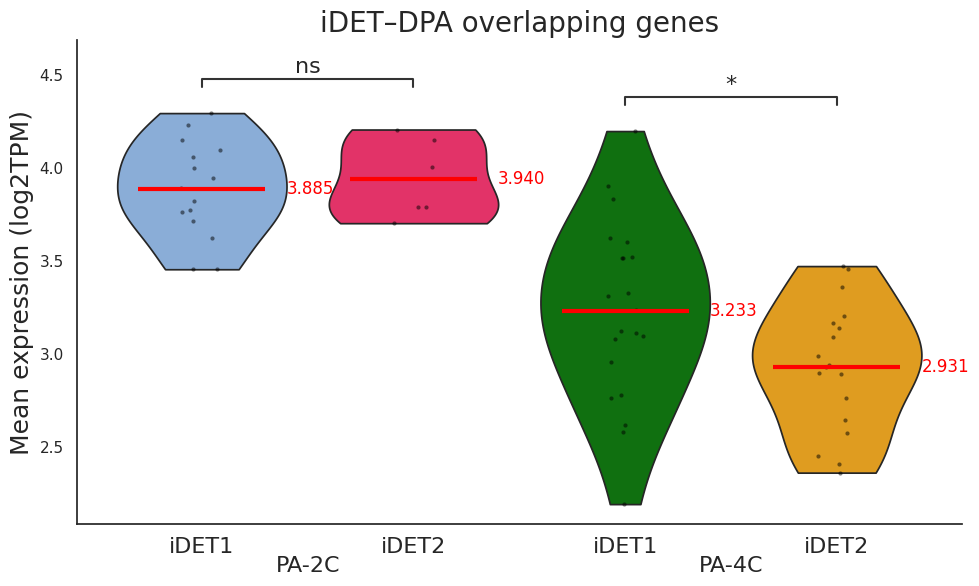

In [5]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
from scipy.stats import mannwhitneyu

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False
sns.set(style="white")

def get_stage_means(expr_file, group_file, gene_file,
                    stage_name, group1_name, group2_name,
                    color1, color2):
    # 读取表达矩阵
    expr = pd.read_csv(expr_file, sep="\t", index_col=0)
    # 读取分组信息
    group_info = pd.read_csv(group_file, sep="\t", header=None, names=["cell", "group"])
    group_dict = dict(zip(group_info["cell"], group_info["group"]))

    # 保留同时存在于表达矩阵和分组中的细胞
    cells_in_use = [c for c in expr.columns if c in group_dict]
    expr = expr[cells_in_use]

    # 构建 group_df（与原代码完全一致）
    group_df = pd.DataFrame({
        "cell": expr.columns,
        "group": [group_dict[c] for c in expr.columns]
    })

    # 读取该阶段的基因列表
    with open(gene_file) as f:
        target_genes = [line.strip() for line in f if line.strip()]
    expr_target = expr.loc[expr.index.intersection(target_genes)]

    # 提取两组细胞的细胞名（基于 group_df，确保存在于 expr 中）
    cells_g1 = group_df[group_df["group"] == group1_name]["cell"].values
    cells_g2 = group_df[group_df["group"] == group2_name]["cell"].values

    # 每个细胞中目标基因集的平均表达值
    means_g1 = expr_target[cells_g1].mean()
    means_g2 = expr_target[cells_g2].mean()

    # 构建返回的 DataFrame
    df_stage = pd.DataFrame({
        "value": list(means_g1) + list(means_g2),
        "group": [f"{stage_name}-R1"] * len(means_g1) + [f"{stage_name}-R2"] * len(means_g2)
    })
    df_stage["stage"] = stage_name

    color_dict = {
        f"{stage_name}-R1": color1,
        f"{stage_name}-R2": color2
    }
    return df_stage, color_dict

# 处理 PA-2C
df_2c, color_2c = get_stage_means(
    expr_file="PA_2C_all_log2TPM_dip.txt",
    group_file="PA_2C_iDET_cluster.txt",
    gene_file="PA_R2C_iDET_DPA_overlap_id.txt",
    stage_name="PA-2C",
    group1_name="PA-2C-iDET1",
    group2_name="PA-2C-iDET2",
    color1="#7dace4",
    color2="#ff165d"
)

# 处理 PA-4C
df_4c, color_4c = get_stage_means(
    expr_file="PA_4C_all_log2TPM_dip.txt",
    group_file="PA_4C_iDET_cluster.txt",
    gene_file="PA_R4C_iDET_DPA_overlap_id.txt",
    stage_name="PA-4C",
    group1_name="PA-4C-iDET1",
    group2_name="PA-4C-iDET2",
    color1="green",
    color2="orange"
)

# 合并数据
df = pd.concat([df_2c, df_4c], ignore_index=True)

# ========== 验证统计显著性（与原代码对比）==========
vals_2c_r1 = df[df["group"] == "PA-2C-R1"]["value"]
vals_2c_r2 = df[df["group"] == "PA-2C-R2"]["value"]
_, p_2c = mannwhitneyu(vals_2c_r1, vals_2c_r2)
print(f"PA-2C Mann-Whitney p = {p_2c}")

vals_4c_r1 = df[df["group"] == "PA-4C-R1"]["value"]
vals_4c_r2 = df[df["group"] == "PA-4C-R2"]["value"]
_, p_4c = mannwhitneyu(vals_4c_r1, vals_4c_r2)
print(f"PA-4C Mann-Whitney p = {p_4c}")

# ========== 绘图 ==========
order = ["PA-2C-R1", "PA-2C-R2", "PA-4C-R1", "PA-4C-R2"]
palette = {**color_2c, **color_4c}

fig, ax = plt.subplots(figsize=(10, 6))

# 小提琴图（无内部箱线）
sns.violinplot(x="group", y="value", data=df, order=order, palette=palette,
               inner=None, cut=0, ax=ax)

# 黑色散点
sns.stripplot(x="group", y="value", data=df, order=order,
              color="black", size=3, alpha=0.5, ax=ax)

# 红色均值线 + 数值标注
means = df.groupby("group")["value"].mean()
for i, g in enumerate(order):
    m = means[g]
    ax.hlines(y=m, xmin=i-0.3, xmax=i+0.3, color="red", linewidth=3, zorder=5)
    ax.text(i+0.4, m, f"{m:.3f}", color="red", ha="left", va="center", fontsize=12)

# 统计检验（组内比较）
pairs = [("PA-2C-R1", "PA-2C-R2"), ("PA-4C-R1", "PA-4C-R2")]
annotator = Annotator(ax, pairs, data=df, x="group", y="value", order=order)
annotator.configure(test="Mann-Whitney", text_format="star", loc="inside", fontsize=16)
annotator.apply_and_annotate()

# X 轴标签美化
ax.set_xticklabels(["iDET1", "iDET2", "iDET1", "iDET2"], fontsize=16)
ax.text(0.5, -0.10, "PA-2C", transform=ax.get_xaxis_transform(), ha="center", fontsize=16)
ax.text(2.5, -0.10, "PA-4C", transform=ax.get_xaxis_transform(), ha="center", fontsize=16)

ax.set_ylabel("Mean expression (log2TPM)", fontsize=18)
ax.set_xlabel("")
ax.set_title("iDET–DPA overlapping genes", fontsize=20)
ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig("PA_2C_4C_iDET_DPA_merged.svg", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_1824540/2006320655.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  group_info = group_info.applymap(lambda x: x.strip() if isinstance(x, str) else x)
/home/lihaoxing/tmp/ipykernel_1824540/2006320655.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  group_info = group_info.applymap(lambda x: x.strip() if isinstance(x, str) else x)
/home/lihaoxing/tmp/ipykernel_1824540/2006320655.py:123: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

IVF-2C-R1 vs. IVF-2C-R2: Mann-Whitney-Wilcoxon test two-sided, P_val:2.114e-05 U_stat=3.650e+02
IVF-4C-R1 vs. IVF-4C-R2: Mann-Whitney-Wilcoxon test two-sided, P_val:2.684e-05 U_stat=5.400e+02


/home/lihaoxing/tmp/ipykernel_1824540/2006320655.py:177: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(["iDEG1", "iDEG2", "iDEG1", "iDEG2"], fontsize=16)


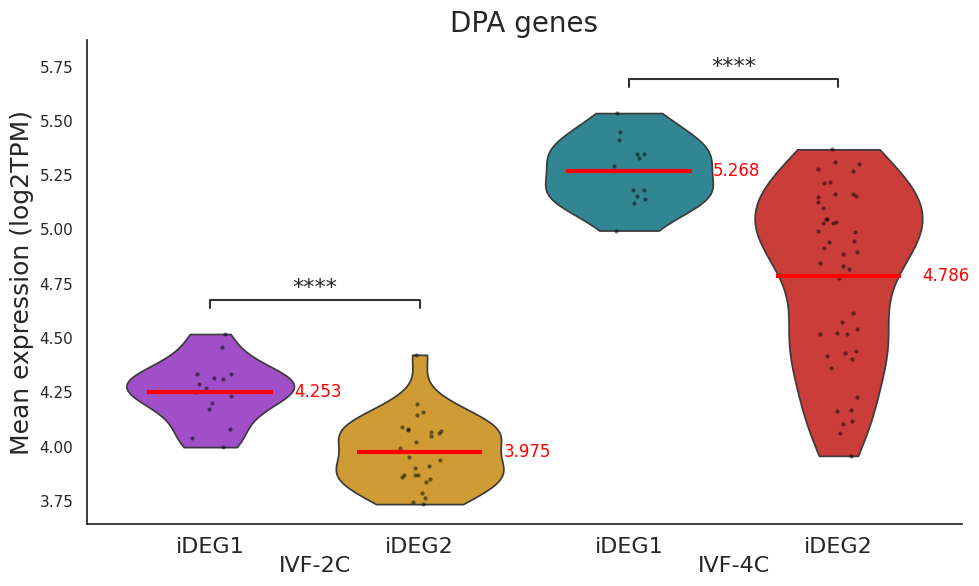

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import numpy as np

# ========== 全局绘图设置 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False
sns.set(style="white")

# ========== 1. 读取 DPA 基因列表 ==========
with open("dpaid.txt") as f:
    dpa_genes = [line.strip() for line in f if line.strip()]

# ========== 2. 定义函数，为每个 stage 构建小提琴图所需的数据 ==========
def build_violin_data(expr_file, group_file, stage_label):
    """
    返回：
        df: 包含 value, group, stage 列的 DataFrame
        order: 该 stage 的两个组名列表（用于后续绘图顺序）
    """
    # 读取表达矩阵
    expr = pd.read_csv(expr_file, sep="\t", index_col=0)
    
    # 读取分组文件，自动检测列顺序（第一列可能是细胞名或组名）
    group_info = pd.read_csv(group_file, sep="\t", header=None)
    # 清理空格
    group_info = group_info.applymap(lambda x: x.strip() if isinstance(x, str) else x)
    
    # 根据列数判断格式（通常为两列）
    if group_info.shape[1] == 2:
        # 尝试判断哪一列是细胞名：检查是否与表达矩阵列名有交集
        col0_match = sum(group_info[0].isin(expr.columns))
        col1_match = sum(group_info[1].isin(expr.columns))
        if col0_match >= col1_match:
            # 第一列是细胞名，第二列是组名
            group_info.columns = ["cell", "group"]
        else:
            # 第二列是细胞名，第一列是组名
            group_info.columns = ["group", "cell"]
    else:
        raise ValueError(f"{group_file} 列数不为2，实际为 {group_info.shape[1]}")
    
    # 构建细胞到组名的映射
    group_dict = dict(zip(group_info["cell"], group_info["group"]))
    
    # 只保留表达矩阵中存在于分组字典的细胞
    cells_in_use = [c for c in expr.columns if c in group_dict]
    expr = expr[cells_in_use]
    
    # 【关键修正】同步更新分组字典，只保留实际存在于 expr 中的细胞
    group_dict = {c: g for c, g in group_dict.items() if c in cells_in_use}
    
    # 提取该 stage 的组名（去重）
    groups = sorted(set(group_dict.values()))
    if len(groups) != 2:
        raise ValueError(f"{stage_label}: 组别数量不为2，实际为 {len(groups)}")
    g1, g2 = groups[0], groups[1]
    
    # 提取两组细胞列表（此时肯定都在 expr 中）
    cells_g1 = [c for c, g in group_dict.items() if g == g1]
    cells_g2 = [c for c, g in group_dict.items() if g == g2]
    
    # 只保留 DPA 基因
    expr_dpa = expr.loc[expr.index.intersection(dpa_genes)]
    
    # 若没有匹配到任何基因，发出警告并返回空数据（避免后续错误）
    if len(expr_dpa) == 0:
        print(f"警告：{stage_label} 没有匹配到任何 DPA 基因，请检查基因名格式！")
        # 返回一个空 DataFrame 和占位顺序
        empty_df = pd.DataFrame(columns=["value", "group", "stage"])
        return empty_df, [f"{stage_label}-R1", f"{stage_label}-R2"]
    
    # 每个细胞中 DPA 基因的平均表达
    mean_g1 = expr_dpa[cells_g1].mean()
    mean_g2 = expr_dpa[cells_g2].mean()
    
    # 构建 DataFrame
    df_stage = pd.DataFrame({
        "value": list(mean_g1) + list(mean_g2),
        "group": [f"{stage_label}-R1"] * len(mean_g1) + [f"{stage_label}-R2"] * len(mean_g2)
    })
    df_stage["stage"] = stage_label
    
    return df_stage, [f"{stage_label}-R1", f"{stage_label}-R2"]

# ========== 3. 分别处理 2C 和 4C 数据 ==========
df_2c, order_2c = build_violin_data(
    expr_file="IVF_2C_all_log2TPM.txt",
    group_file="IVF_2C_iDEG_cluster.txt",
    stage_label="IVF-2C"
)

df_4c, order_4c = build_violin_data(
    expr_file="IVF_4C_all_log2TPM.txt",
    group_file="IVF_4C_iDEG_cluster.txt",
    stage_label="IVF-4C"
)

# 合并
df = pd.concat([df_2c, df_4c], ignore_index=True)

# 检查合并后是否有数据
if df.empty:
    raise ValueError("合并后的数据框为空，请检查基因匹配或分组文件。")

# ========== 4. 定义绘图顺序和颜色 ==========
order = ["IVF-2C-R1", "IVF-2C-R2", "IVF-4C-R1", "IVF-4C-R2"]

palette = {
    "IVF-2C-R1": "#A73BDD",
    "IVF-2C-R2": "#E7A31B",
    "IVF-4C-R1": "#2292A4",
    "IVF-4C-R2": "#E22720"
}

# ========== 5. 绘图 ==========
fig, ax = plt.subplots(figsize=(10, 6))

# 小提琴图
sns.violinplot(
    x="group",
    y="value",
    data=df,
    order=order,
    palette=palette,
    inner=None,           # 去掉内部 box/线，后面用红线和散点
    cut=0,
    ax=ax
)

# 散点（黑点）
sns.stripplot(
    x="group",
    y="value",
    data=df,
    order=order,
    color="black",
    size=3,
    alpha=0.5,
    ax=ax
)

# 均值红线 + 数值标注（红色）
means = df.groupby("group")["value"].mean()
for i, g in enumerate(order):
    m = means[g]
    ax.hlines(y=m, xmin=i-0.3, xmax=i+0.3, color="red", linewidth=3, zorder=5)
    ax.text(i+0.4, m, f"{m:.3f}", color="red", ha="left", va="center", fontsize=12)

# ========== 6. 统计检验（分别比较每个阶段内的两个重复）==========
pairs = [
    ("IVF-2C-R1", "IVF-2C-R2"),
    ("IVF-4C-R1", "IVF-4C-R2")
]

annotator = Annotator(
    ax,
    pairs,
    data=df,
    x="group",
    y="value",
    order=order
)
annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    fontsize=16
)
annotator.apply_and_annotate()

# ========== 7. X 轴标签美化 ==========
# 设置刻度标签为 iDET1 / iDET2 (与您的分组对应)
ax.set_xticklabels(["iDEG1", "iDEG2", "iDEG1", "iDEG2"], fontsize=16)

# 添加阶段分组标签（位于 x 轴下方）
ax.text(0.5, -0.10, "IVF-2C", transform=ax.get_xaxis_transform(), ha="center", fontsize=16)
ax.text(2.5, -0.10, "IVF-4C", transform=ax.get_xaxis_transform(), ha="center", fontsize=16)

# ========== 8. 轴标签、标题、样式 ==========
ax.set_ylabel("Mean expression (log2TPM)", fontsize=18)
ax.set_xlabel("")
ax.set_title("DPA genes", fontsize=20)

ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig("DPA_IVF_2C_4C_merged.svg", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

/home/lihaoxing/tmp/ipykernel_1824540/4157736430.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  group_info = group_info.applymap(lambda x: x.strip() if isinstance(x, str) else x)
/home/lihaoxing/tmp/ipykernel_1824540/4157736430.py:30: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  group_info = group_info.applymap(lambda x: x.strip() if isinstance(x, str) else x)
/home/lihaoxing/tmp/ipykernel_1824540/4157736430.py:120: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

PA-2C-R1 vs. PA-2C-R2: Mann-Whitney-Wilcoxon test two-sided, P_val:7.333e-01 U_stat=5.000e+01
PA-4C-R1 vs. PA-4C-R2: Mann-Whitney-Wilcoxon test two-sided, P_val:8.988e-03 U_stat=2.760e+02


/home/lihaoxing/tmp/ipykernel_1824540/4157736430.py:174: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(["iDEG1", "iDEG2", "iDEG1", "iDEG2"], fontsize=16)


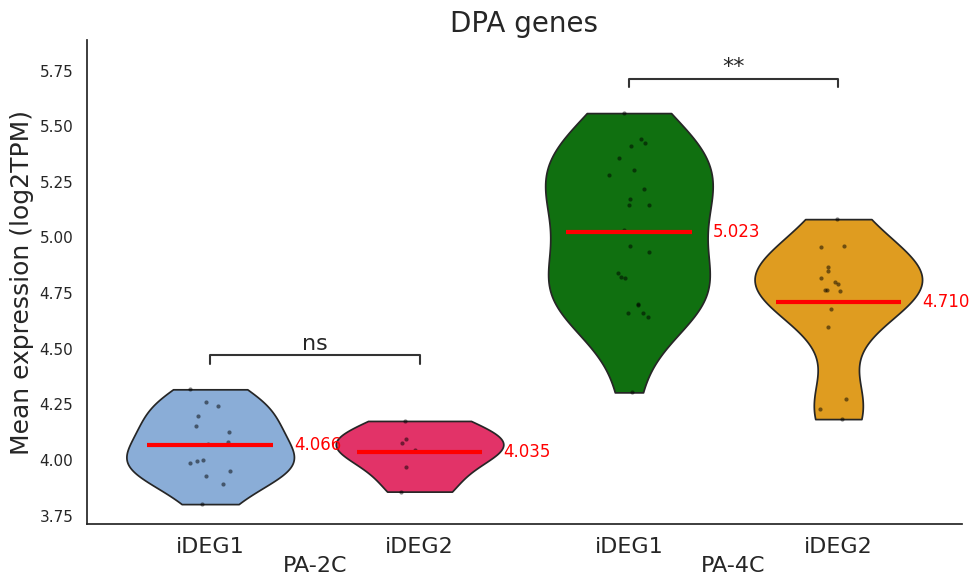

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator
import numpy as np

# ========== 全局绘图设置 ==========
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['axes.unicode_minus'] = False
sns.set(style="white")

# ========== 1. 读取 DPA 基因列表 ==========
with open("dpaid.txt") as f:
    dpa_genes = [line.strip() for line in f if line.strip()]

# ========== 2. 构建数据的函数（增强健壮性） ==========
def build_violin_data(expr_file, group_file, stage_label):
    """
    返回：
        df: 包含 value, group, stage 列的 DataFrame
        order: 该 stage 的两个组名列表（用于后续绘图顺序）
    """
    # 读取表达矩阵
    expr = pd.read_csv(expr_file, sep="\t", index_col=0)
    
    # 读取分组文件，自动检测列顺序（第一列可能是细胞名或组名）
    group_info = pd.read_csv(group_file, sep="\t", header=None)
    # 清理字符串空格
    group_info = group_info.applymap(lambda x: x.strip() if isinstance(x, str) else x)
    
    # 根据列数判断格式（通常为两列）
    if group_info.shape[1] == 2:
        # 判断哪一列是细胞名：检查与表达矩阵列名的交集数量
        col0_match = sum(group_info[0].isin(expr.columns))
        col1_match = sum(group_info[1].isin(expr.columns))
        if col0_match >= col1_match:
            group_info.columns = ["cell", "group"]      # 第一列是细胞名
        else:
            group_info.columns = ["group", "cell"]      # 第二列是细胞名
    else:
        raise ValueError(f"{group_file} 列数不为2，实际为 {group_info.shape[1]}")
    
    # 构建细胞→组名映射
    group_dict = dict(zip(group_info["cell"], group_info["group"]))
    
    # 只保留表达矩阵中存在于分组字典的细胞
    cells_in_use = [c for c in expr.columns if c in group_dict]
    expr = expr[cells_in_use]
    
    # 同步更新分组字典，只保留实际存在于 expr 中的细胞
    group_dict = {c: g for c, g in group_dict.items() if c in cells_in_use}
    
    # 提取该 stage 的组名（去重）
    groups = sorted(set(group_dict.values()))
    if len(groups) != 2:
        raise ValueError(f"{stage_label}: 组别数量不为2，实际为 {len(groups)}")
    g1, g2 = groups[0], groups[1]
    
    # 提取两组细胞列表（此时肯定都在 expr 中）
    cells_g1 = [c for c, g in group_dict.items() if g == g1]
    cells_g2 = [c for c, g in group_dict.items() if g == g2]
    
    # 只保留 DPA 基因
    expr_dpa = expr.loc[expr.index.intersection(dpa_genes)]
    
    # 若没有匹配到任何基因，发出警告并返回空数据
    if len(expr_dpa) == 0:
        print(f"警告：{stage_label} 没有匹配到任何 DPA 基因，请检查基因名格式！")
        empty_df = pd.DataFrame(columns=["value", "group", "stage"])
        return empty_df, [f"{stage_label}-R1", f"{stage_label}-R2"]
    
    # 每个细胞中 DPA 基因的平均表达
    mean_g1 = expr_dpa[cells_g1].mean()
    mean_g2 = expr_dpa[cells_g2].mean()
    
    # 构建 DataFrame
    df_stage = pd.DataFrame({
        "value": list(mean_g1) + list(mean_g2),
        "group": [f"{stage_label}-R1"] * len(mean_g1) + [f"{stage_label}-R2"] * len(mean_g2)
    })
    df_stage["stage"] = stage_label
    
    return df_stage, [f"{stage_label}-R1", f"{stage_label}-R2"]

# ========== 3. 分别处理 2C 和 4C 数据 ==========
df_2c, order_2c = build_violin_data(
    expr_file="PA_2C_all_log2TPM.txt",
    group_file="PA_2C_iDEG_cluster.txt",
    stage_label="PA-2C"
)

df_4c, order_4c = build_violin_data(
    expr_file="PA_4C_all_log2TPM.txt",
    group_file="PA_4C_iDEG_cluster.txt",
    stage_label="PA-4C"
)

# 合并
df = pd.concat([df_2c, df_4c], ignore_index=True)

# 检查合并后是否有数据
if df.empty:
    raise ValueError("合并后的数据框为空，请检查基因匹配或分组文件。")

# ========== 4. 定义绘图顺序和颜色 ==========
order = ["PA-2C-R1", "PA-2C-R2", "PA-4C-R1", "PA-4C-R2"]

palette = {
    "PA-2C-R1": "#7dace4",
    "PA-2C-R2": "#ff165d",
    "PA-4C-R1": "green",
    "PA-4C-R2": "orange"
}

# ========== 5. 绘图 ==========
fig, ax = plt.subplots(figsize=(10, 6))

# 小提琴图
sns.violinplot(
    x="group",
    y="value",
    data=df,
    order=order,
    palette=palette,
    inner=None,           # 去掉内部 box/线，后面用红线和散点
    cut=0,
    ax=ax
)

# 散点（黑点）
sns.stripplot(
    x="group",
    y="value",
    data=df,
    order=order,
    color="black",
    size=3,
    alpha=0.5,
    ax=ax
)

# 均值红线 + 数值标注（红色）
means = df.groupby("group")["value"].mean()
for i, g in enumerate(order):
    m = means[g]
    ax.hlines(y=m, xmin=i-0.3, xmax=i+0.3, color="red", linewidth=3, zorder=5)
    ax.text(i+0.4, m, f"{m:.3f}", color="red", ha="left", va="center", fontsize=12)

# ========== 6. 统计检验（分别比较每个阶段内的两个重复）==========
pairs = [
    ("PA-2C-R1", "PA-2C-R2"),
    ("PA-4C-R1", "PA-4C-R2")
]

annotator = Annotator(
    ax,
    pairs,
    data=df,
    x="group",
    y="value",
    order=order
)
annotator.configure(
    test="Mann-Whitney",
    text_format="star",
    loc="inside",
    fontsize=16
)
annotator.apply_and_annotate()

# ========== 7. X 轴标签美化 ==========
# 将刻度标签改为 iDET1 / iDET2（与您的分组对应）
ax.set_xticklabels(["iDEG1", "iDEG2", "iDEG1", "iDEG2"], fontsize=16)

# 添加阶段分组标签（位于 x 轴下方）
ax.text(0.5, -0.10, "PA-2C", transform=ax.get_xaxis_transform(), ha="center", fontsize=16)
ax.text(2.5, -0.10, "PA-4C", transform=ax.get_xaxis_transform(), ha="center", fontsize=16)

# ========== 8. 轴标签、标题、样式 ==========
ax.set_ylabel("Mean expression (log2TPM)", fontsize=18)
ax.set_xlabel("")
ax.set_title("DPA genes", fontsize=20)

ax.grid(False)
sns.despine()

plt.tight_layout()
plt.savefig("DPA_PA_2C_4C_merged.svg", dpi=300, bbox_inches="tight", transparent=True)
plt.show()